# Etapa 2 — Mapas de color

**Proyecto:** segmentación de vasos en imágenes de fondo de ojo de la base HRF. Este cuaderno continúa la calibración de `01_contexto.ipynb` y la detección del campo de visión de `01b_campo_de_vision.ipynb`.

## Pregunta y objetivo

**¿Qué representación del color permite distinguir mejor los píxeles de vaso de los de fondo antes de aplicar mejoramiento o filtros de realce?**

Una fotografía RGB tiene tres valores por píxel. En esta etapa se obtienen distintas combinaciones de esos valores, llamadas **mapas**. Cada mapa entrega un valor continuo por píxel; todavía no es una máscara de vasos.

Se comparan diez representaciones: rojo, verde, azul, escala de grises, L*, a* y b* de Lab, y tres componentes principales (PC1, PC2 y PC3). El objetivo es identificar candidatas para los próximos experimentos y mantener el canal verde como referencia clásica.

## Alcance y criterios utilizados

- Se usan **solo las 30 imágenes de desarrollo**, correspondientes a 18 personas según la agrupación inferida y guardada en `data/split.csv`. Las 15 imágenes de prueba quedan reservadas.
- La comparación se realiza a **resolución original**. No se aplican todavía corrección de iluminación, restauración, realce ni umbral de segmentación.
- La referencia es la máscara de vasos del experto. Para evaluar se consideran únicamente los píxeles dentro del campo de visión de la base.
- La medida es el área bajo la curva ROC (**AUC**) por imagen. Se resumen las imágenes con el mismo peso, sin reunir todos sus píxeles en una única AUC.
- Se exploran ambos sentidos del mapa: vasos oscuros o claros. Después se fija **un sentido por mapa**, el que tiene mayor AUC media en desarrollo; no se elige uno distinto para cada fotografía.
- Se comparan diferencias apareadas frente al mapa de mayor media mediante 2.000 remuestreos de personas completas, con semilla 2026. El margen de no inferioridad de 0,02 procede del plan del repositorio.

**Estado de este cuaderno.** El texto explicativo organiza experimentos que ya se ejecutaron. No se presenta como un protocolo escrito antes de observar los resultados. Los resultados de desarrollo son exploratorios y optimistas: la selección de sentido y mapa usa el mismo conjunto que se resume. La decisión al final es provisional y permite avanzar con las siguientes etapas.

## Recorrido

1. Preparar Colab y cargar los datos.
2. Explorar RGB, gris y Lab; interpretar histogramas y AUC.
3. Obtener y evaluar PCA.
4. Repetir la comparación en desarrollo y estimar las diferencias por personas.
5. Registrar una decisión y sus límites.


> **Cambios del 26/10/2026 (Augusto), sin tocar el análisis ni los textos de resultados:**
> - el archivo se llamaba `02_mapas_cololr.ipynb`;
> - la preparación ahora funciona en Colab y en una computadora con el repositorio clonado;
> - `auc_vasos_oscuros` y `crear_mapas` usan las funciones de `src/metrics.py` (`auc`) y `src/color.py` (`color_maps`), que tienen pruebas automáticas; la definición de los mapas y la regla de signo son las mismas;
> - el cuaderno se volvió a correr completo y los resultados coinciden con los originales.

## 1. Preparación del entorno

Funciona en Google Colab y en una computadora con el repositorio clonado. En Colab se monta Drive y `ROOT` es la carpeta del proyecto en Mi unidad (cambiar la ruta si está en otro lugar); en una computadora, `ROOT` es la carpeta del repositorio. Después se instalan las bibliotecas (solo en Colab) y se descarga la base si todavía no está en `data/raw/`.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

try:
    import google.colab  # noqa: F401
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/TP-PSI-G8-main")
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

assert (ROOT / "src").is_dir(), "No encuentro la carpeta src. Revisá ROOT."
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

if EN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
if not (ROOT / "data" / "raw" / "images").is_dir():
    subprocess.run([sys.executable, "scripts/download_data.py"], check=True)

print("Carpeta de trabajo:", Path.cwd(), "| Colab:", EN_COLAB)

Carpeta de trabajo: C:\Users\afrat\proyectos\Python ITBA\PSIB2026Q2-TPI-Grupo08-Frate_Tenca_Weizman | Colab: False


### 1.5 Leer la partición de desarrollo y prueba

`dev_ids()` devuelve los identificadores de desarrollo; `load_split()` lee la partición ya guardada. `set_index("image")` permite consultar la información por identificador. La salida esperada es **30 imágenes de desarrollo**.

No se vuelve a generar la partición. Las funciones habituales de carga del repositorio bloquean las imágenes reservadas para prueba.


In [2]:
from src.data import dev_ids, load_split

ids = dev_ids()
split = load_split().set_index("image")

print(len(ids), "imágenes de desarrollo")

30 imágenes de desarrollo


## 2. Exploración de una imagen de desarrollo

### 2.1 Fotografía y máscaras de referencia

Se usa la primera imagen de `dev_ids()`, **01_h**, como ejemplo para comprender el procedimiento antes de extenderlo a desarrollo.

| Variable | Contenido | Interpretación |
|---|---|---|
| `rgb` | Fotografía a color | Entrada de los mapas |
| `vasos` | Máscara manual de vasos | `True` o blanco significa vaso según el experto |
| `campo` | Campo de visión de la base | `True` o blanco significa zona de retina donde se evalúa |

Las dos máscaras tienen funciones distintas: una indica **qué es vaso** y la otra **dónde evaluar**. Mostrarlas permite revisar la correspondencia espacial entre la fotografía y sus referencias. Ninguna de estas máscaras es una predicción del algoritmo.


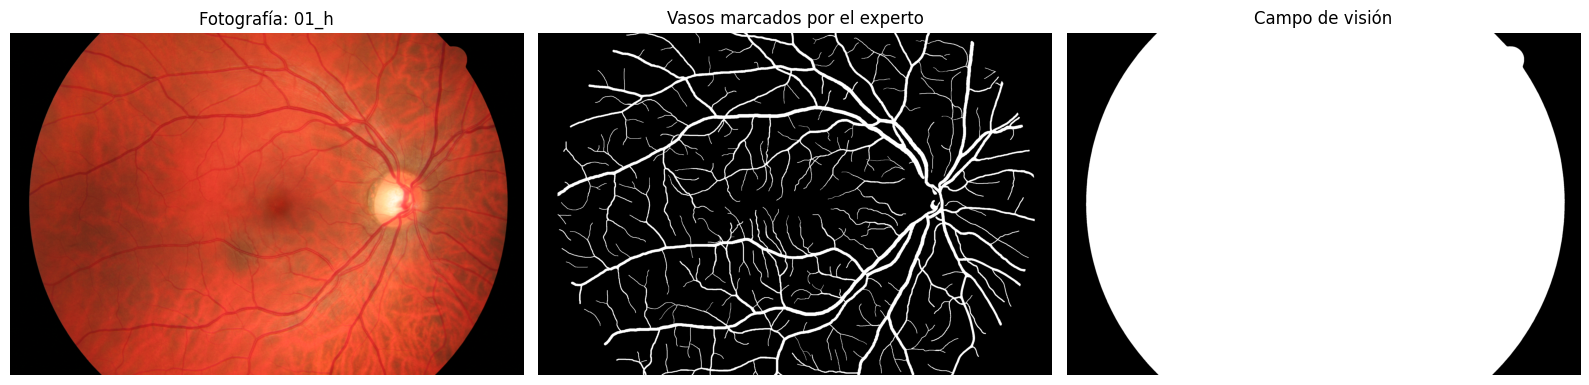

In [3]:
import matplotlib.pyplot as plt
from src.data import load_image, load_vessels, load_fov

# Elegimos la primera imagen del conjunto de desarrollo
image_id = ids[0]

# Cargamos la fotografía y las referencias
rgb = load_image(image_id)
vasos = load_vessels(image_id)
campo = load_fov(image_id)

# Mostramos las tres imágenes
fig, ax = plt.subplots(1, 3, figsize=(16, 5))

ax[0].imshow(rgb)
ax[0].set_title(f"Fotografía: {image_id}")

ax[1].imshow(vasos, cmap="gray", vmin=0, vmax=1)
ax[1].set_title("Vasos marcados por el experto")

ax[2].imshow(campo, cmap="gray", vmin=0, vmax=1)
ax[2].set_title("Campo de visión")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

**Lectura del ejemplo.** La fotografía, la red de vasos del experto y el campo de visión representan el mismo ojo. Los vasos blancos de la referencia deben corresponder a las líneas vasculares visibles. La gran región blanca del campo de visión no indica vasos: delimita dónde evaluar.


### 2.2 Canales rojo, verde y azul

`rgb[:, :, 0]`, `rgb[:, :, 1]` y `rgb[:, :, 2]` extraen las intensidades de rojo, verde y azul. Se muestran en gris para observar la información de cada canal: un píxel claro indica mayor intensidad de ese canal.

Los tres se visualizan con la misma escala, de 0 a 255. Se busca observar contraste vaso–fondo, visibilidad de ramas finas y variaciones de iluminación. La inspección visual orienta, pero no decide por sí sola qué mapa conviene.


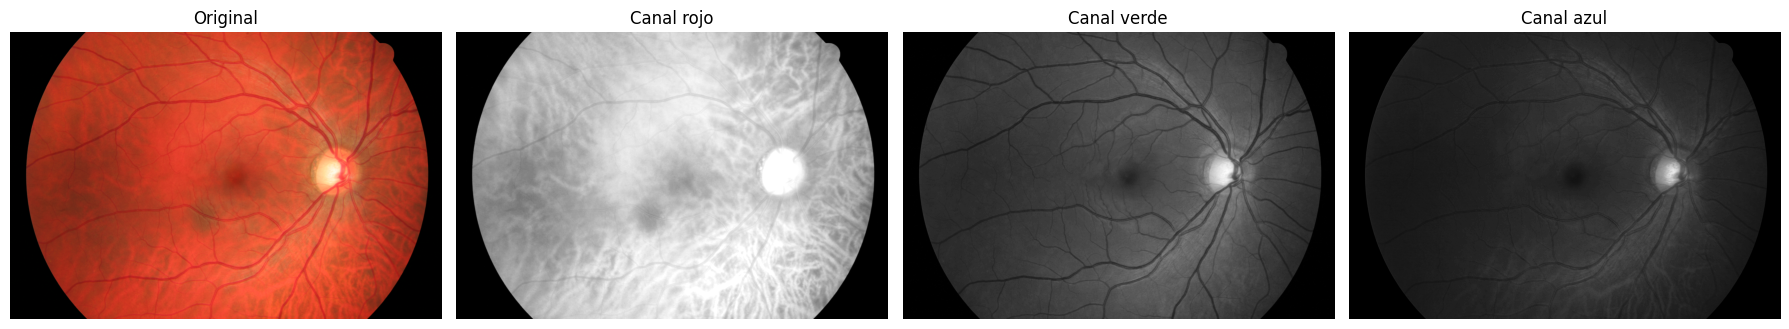

In [4]:
# Cada canal contiene la intensidad de un color
rojo = rgb[:, :, 0]
verde = rgb[:, :, 1]
azul = rgb[:, :, 2]

fig, ax = plt.subplots(1, 4, figsize=(18, 5))

ax[0].imshow(rgb)
ax[0].set_title("Original")

for a, canal, nombre in zip(
    ax[1:],
    [rojo, verde, azul],
    ["Canal rojo", "Canal verde", "Canal azul"]
):
    a.imshow(canal, cmap="gray", vmin=0, vmax=255)
    a.set_title(nombre)

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

**Observación exploratoria en 01_h.** El canal verde permite distinguir visualmente varios vasos oscuros respecto del fondo. El rojo aparece muy claro y con textura de fondo; el azul es más oscuro y algunas ramas resultan menos visibles. También hay variaciones de iluminación. Esta observación se contrasta con AUC antes de elegir un mapa.


### 2.3 Escala de grises y espacio Lab

La escala de grises combina los canales RGB con una ponderación mayor del verde. Lab separa la claridad (**L***) de dos ejes de color: **a***, de verde a rojo, y **b***, de azul a amarillo. En a* y b*, claro u oscuro representa la posición en un eje de color, no directamente el brillo original.

Para visualizar se oculta el exterior del campo de visión y se ajusta el contraste de cada mapa entre sus percentiles 1 y 99 dentro de la retina. **Este ajuste solo afecta la figura**: las AUC posteriores usan los valores originales. Como cada mapa tiene su propia escala de visualización, una apariencia más contrastada no prueba que separe mejor las clases.


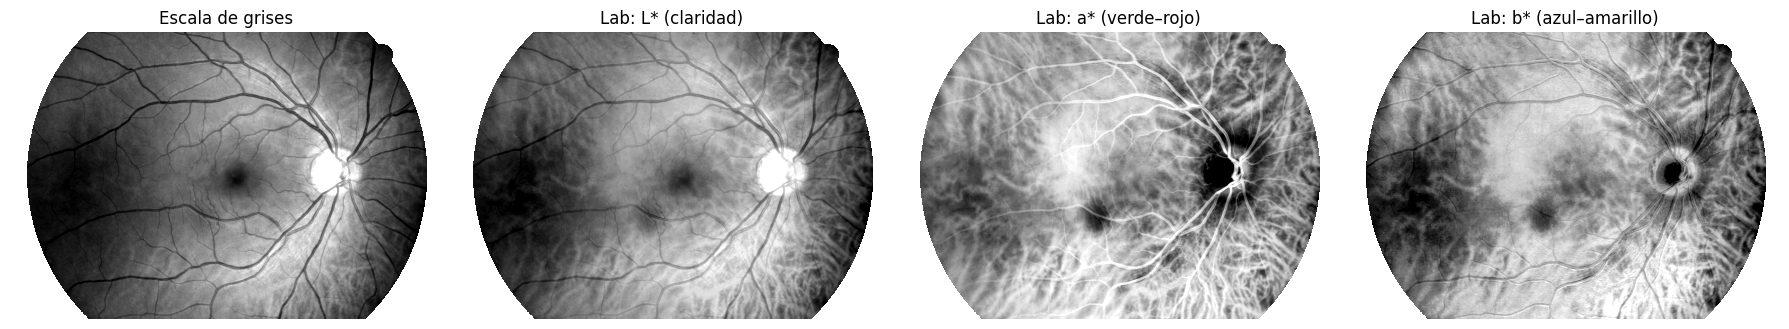

In [5]:
import numpy as np
from skimage.color import rgb2gray, rgb2lab

# Convertimos la fotografía a valores entre 0 y 1
rgb_float = rgb.astype(np.float32) / 255.0

# Obtenemos las nuevas representaciones
gris = rgb2gray(rgb_float)
lab = rgb2lab(rgb_float)

L = lab[:, :, 0]
a = lab[:, :, 1]
b = lab[:, :, 2]

mapas_nuevos = {
    "Escala de grises": gris,
    "Lab: L* (claridad)": L,
    "Lab: a* (verde–rojo)": a,
    "Lab: b* (azul–amarillo)": b,
}

fig, ax = plt.subplots(1, 4, figsize=(18, 5))

for eje, (nombre, mapa) in zip(ax, mapas_nuevos.items()):
    # Ajustamos solo la visualización usando la zona de retina
    minimo, maximo = np.percentile(mapa[campo], [1, 99])

    # Ocultamos el exterior del campo de visión
    visible = np.ma.masked_where(~campo, mapa)

    eje.imshow(
        visible,
        cmap="gray",
        vmin=minimo,
        vmax=maximo
    )
    eje.set_title(nombre)
    eje.set_facecolor("black")
    eje.axis("off")

plt.tight_layout()
plt.show()

**Observación exploratoria.** En esta fotografía la escala de grises permite seguir bien los vasos. L* también conserva variaciones del fondo. En a* varios vasos aparecen claros, junto con textura, por lo que hace falta evaluar ambos sentidos. La inspección no permite descartar mapas ni comparar definitivamente su desempeño.


### 2.4 Histogramas de vasos y fondo

La máscara del experto permite separar los valores en dos grupos: `campo & vasos` (vasos) y `campo & ~vasos` (fondo dentro de la retina). Se comparan primero verde y gris para comprender cómo se relaciona su aspecto con la distribución de intensidades.

El eje horizontal indica intensidad entre 0 y 1. Se usa **densidad**, no cantidad de píxeles, para comparar la forma de las distribuciones aunque haya más fondo que vasos. Cada distribución tiene área total uno; la altura de las barras puede superar uno.

Cuanto mayor sea la superposición, más difícil será distinguir vaso y fondo usando solamente un umbral global de intensidad.


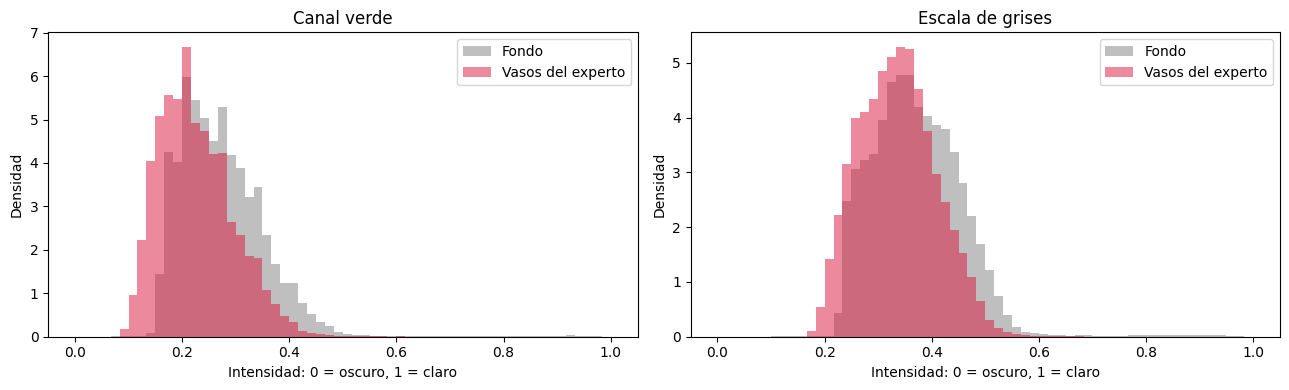

In [6]:
# Separamos los píxeles según la referencia del experto
zona_vasos = campo & vasos
zona_fondo = campo & ~vasos

mapas_comparar = {
    "Canal verde": verde.astype(np.float32) / 255.0,
    "Escala de grises": gris,
}

fig, ax = plt.subplots(1, 2, figsize=(13, 4))

# Mismos intervalos para ambos mapas
intervalos = np.linspace(0, 1, 61)

for eje, (nombre, mapa) in zip(ax, mapas_comparar.items()):
    eje.hist(
        mapa[zona_fondo],
        bins=intervalos,
        density=True,
        alpha=0.5,
        color="gray",
        label="Fondo"
    )

    eje.hist(
        mapa[zona_vasos],
        bins=intervalos,
        density=True,
        alpha=0.5,
        color="crimson",
        label="Vasos del experto"
    )

    eje.set_title(nombre)
    eje.set_xlabel("Intensidad: 0 = oscuro, 1 = claro")
    eje.set_ylabel("Densidad")
    eje.legend()

plt.tight_layout()
plt.show()

**Interpretación.** En verde y gris, los vasos tienden a tener intensidades menores, pero las distribuciones se superponen ampliamente. Un mismo valor puede pertenecer a un vaso o a una región oscura del fondo. Esto motiva estudiar más adelante corrección de iluminación y realce de estructuras; aquí se mantiene la referencia sin procesamiento.


### 2.5 Medida de separación: AUC

La AUC resume qué tan bien un mapa ordena los píxeles de vaso frente a los de fondo a través de todos los umbrales posibles. Para el sentido **vasos oscuros**, equivale a la probabilidad de que un píxel de vaso tenga menor intensidad que uno de fondo, contando los empates a la mitad.

| AUC | Lectura |
|---|---|
| 0,5 | Sin separación por orden de intensidad |
| Próxima a 1 | Buena separación con el sentido elegido |
| Menor que 0,5 | Predomina el sentido contrario |

La función cambia el signo para que menor intensidad equivalga a mayor puntuación de vaso. Calcula la AUC mediante rangos, con rango promedio para los empates. No necesita seleccionar un umbral ni generar una máscara.

**AUC no es exactitud ni sensibilidad:** una AUC de 0,75 no significa que se detectó el 75 % de los vasos.


In [7]:
import numpy as np
import pandas as pd

from src.metrics import auc


def auc_vasos_oscuros(mapa, referencia, region):
    """AUC considerando que una intensidad menor indica vaso.

    Usa src.metrics.auc (por rangos, empates a la mitad) con el signo cambiado:
    más oscuro pasa a tener mayor puntuación.
    """
    return auc(-mapa.astype(np.float64), referencia, region)


resultados_auc = pd.DataFrame([
    {
        "Imagen": image_id,
        "Mapa": "Canal verde",
        "AUC": auc_vasos_oscuros(verde, vasos, campo)
    },
    {
        "Imagen": image_id,
        "Mapa": "Escala de grises",
        "AUC": auc_vasos_oscuros(gris, vasos, campo)
    }
])

display(resultados_auc.round(4))

,Imagen,Mapa,AUC
0,01_h,Canal verde,0.6787
1,01_h,Escala de grises,0.6187


**Resultado en 01_h.** Verde obtiene AUC **0,6787** y gris **0,6187**, en el sentido de vasos oscuros. Verde ordena mejor las dos clases por intensidad en esta imagen, aunque gris pareciera favorable visualmente. Reconocer una línea por su forma y separarla usando solo intensidad son tareas distintas.


### 2.6 Comparar los siete mapas RGB, gris y Lab

Se calcula la AUC en los valores originales de cada mapa, siempre dentro del mismo campo de visión de referencia. Se muestran los dos sentidos: para vasos claros la AUC es `1 - AUC vasos oscuros`. No se agrega información al invertir el sentido; cambia la interpretación del valor alto o bajo.

Esta tabla sigue siendo exploratoria de una imagen. El sentido definitivo de cada mapa se establece después con todo desarrollo y se aplica igual a sus imágenes.


In [8]:
from skimage.color import rgb2gray, rgb2lab

# Calculamos los mapas desde la fotografía original
rgb_float = rgb.astype(np.float32) / 255.0
lab = rgb2lab(rgb_float)

mapas = {
    "Rojo": rgb_float[:, :, 0],
    "Verde": rgb_float[:, :, 1],
    "Azul": rgb_float[:, :, 2],
    "Escala de grises": rgb2gray(rgb_float),
    "Lab L*": lab[:, :, 0],
    "Lab a*": lab[:, :, 1],
    "Lab b*": lab[:, :, 2],
}

filas = []

for nombre, mapa in mapas.items():
    auc_oscuros = auc_vasos_oscuros(mapa, vasos, campo)

    filas.append({
        "Imagen": image_id,
        "Mapa": nombre,
        "AUC vasos oscuros": auc_oscuros,
        "AUC vasos claros": 1.0 - auc_oscuros
    })

tabla_mapas = pd.DataFrame(filas)

display(tabla_mapas.round(4))

,Imagen,Mapa,AUC vasos oscuros,AUC vasos claros
0,01_h,Rojo,0.5005,0.4995
1,01_h,Verde,0.6787,0.3213
2,01_h,Azul,0.5273,0.4727
3,01_h,Escala de grises,0.6187,0.3813
4,01_h,Lab L*,0.5600,0.4400
5,01_h,Lab a*,0.3225,0.6775
6,01_h,Lab b*,0.5626,0.4374


**Resultado en 01_h.** Verde con vasos oscuros (**0,6787**) y a* con vasos claros (**0,6775**) tienen valores muy cercanos. La diferencia de 0,0012 en una sola imagen no permite preferir con fundamento uno de ellos. Rojo queda cerca de 0,5. AUC parecidas no demuestran que dos mapas aporten información complementaria.


## 3. Componentes principales del color (PCA)

### 3.1 Obtener tres combinaciones de RGB

PCA obtiene combinaciones lineales de rojo, verde y azul. PC1 recoge la mayor variación del color, PC2 una variación en una dirección perpendicular a la primera y PC3 la restante. Se calcula sobre RGB entre 0 y 1, centrado por su media y **sin estandarizar cada canal por separado**.

Se usa el campo de visión **detectado automáticamente** a partir de la fotografía, sin consultar los vasos del experto. Esto permite calcular PCA con una imagen nueva sin sus anotaciones. La evaluación posterior sigue usando `campo`, la referencia de la base.

La covarianza resume cómo varían conjuntamente los canales. Sus autovectores son las direcciones de proyección y sus autovalores indican la variación de cada dirección. Se ordenan de mayor a menor. Como un autovector y su negativo representan el mismo eje, se fija una convención reproducible: su coeficiente de mayor valor absoluto queda positivo.

**La mayor variación no equivale a la mejor segmentación.** La iluminación y la textura del fondo también aportan variación. Además, PCA se calcula por fotografía: los coeficientes de PC1, PC2 y PC3 pueden cambiar entre imágenes.


In [9]:
from src.fov import detect_fov_robust

# Detectamos la zona de retina sin usar las máscaras del experto
campo_auto = detect_fov_robust(rgb)

# Cada fila contiene el rojo, verde y azul de un píxel de retina
pixeles = rgb_float[campo_auto]

# Calculamos el promedio y cómo varían juntos los canales
media_rgb = pixeles.mean(axis=0, dtype=np.float64)
covarianza = np.cov(pixeles, rowvar=False)

# Obtenemos las tres direcciones principales
valores, vectores = np.linalg.eigh(covarianza)

# Ordenamos desde la mayor variación hasta la menor
orden = np.argsort(valores)[::-1]
valores = valores[orden]
vectores = vectores[:, orden]

# Fijamos un signo reproducible, sin consultar los vasos
for j in range(3):
    posicion = np.argmax(np.abs(vectores[:, j]))
    if vectores[posicion, j] < 0:
        vectores[:, j] *= -1

# Proyectamos la imagen sobre cada dirección
mapas_pca = {}

for j in range(3):
    direccion = vectores[:, j].astype(np.float32)

    mapas_pca[f"PC{j + 1}"] = (
        rgb_float @ direccion - float(media_rgb @ direccion)
    )

# Liberamos la copia de los píxeles usada para el cálculo
del pixeles

print("Variación explicada por cada componente:")
for nombre, porcentaje in zip(
    mapas_pca, 100 * valores / valores.sum()
):
    print(f"{nombre}: {porcentaje:.2f}%")

Variación explicada por cada componente:
PC1: 85.20%
PC2: 13.84%
PC3: 0.96%


**Resultado en 01_h.** PC1 explica **85,20 %**, PC2 **13,84 %** y PC3 **0,96 %** de la variación. Estos porcentajes describen variación de RGB, no proporción de vasos ni aciertos del algoritmo. No se descarta PC3 por su porcentaje pequeño.


### 3.2 Visualización de PCA

Se muestran las tres componentes con ajuste de contraste independiente entre los percentiles 1 y 99 del campo automático. El ajuste es únicamente visual. Se observa qué estructuras resaltan y si los vasos aparecen claros u oscuros.


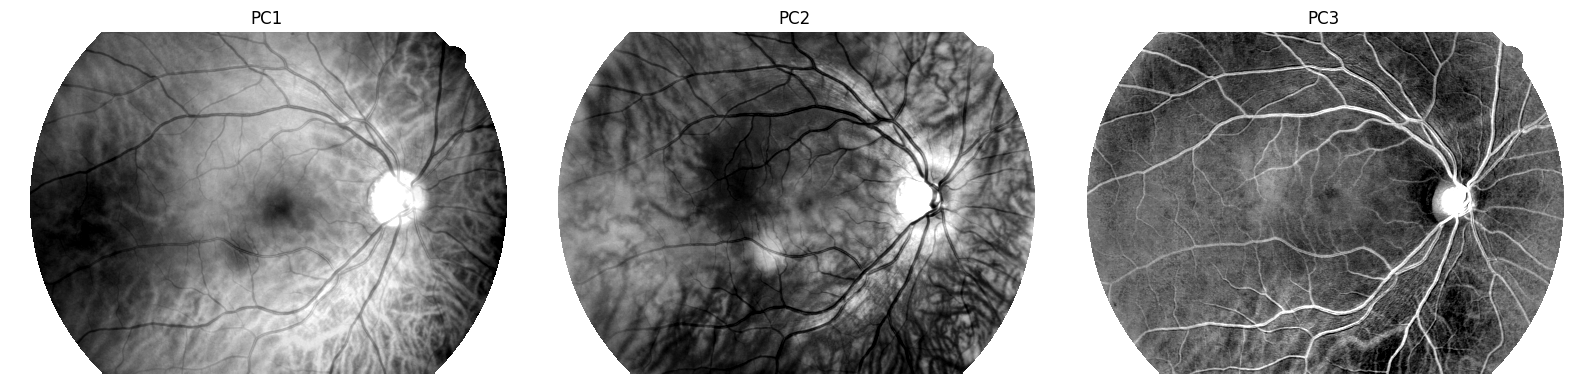

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(16, 5))

for eje, (nombre, mapa) in zip(ax, mapas_pca.items()):
    minimo, maximo = np.percentile(mapa[campo_auto], [1, 99])
    visible = np.ma.masked_where(~campo_auto, mapa)

    eje.imshow(
        visible,
        cmap="gray",
        vmin=minimo,
        vmax=maximo
    )
    eje.set_title(nombre)
    eje.set_facecolor("black")
    eje.axis("off")

plt.tight_layout()
plt.show()

**Observación exploratoria.** En PC1 se conservan grandes diferencias de iluminación y textura; en PC2 se ven vasos oscuros junto con un fondo variable. En PC3 varios vasos aparecen claros sobre fondo oscuro, aunque también hay textura fina. La AUC permite comprobar la separación por valores sin depender del contraste de pantalla.


### 3.3 Evaluación de las diez representaciones en 01_h

Se aplica exactamente la misma función de AUC a PC1, PC2 y PC3 y se reúne su tabla con los siete mapas anteriores. La referencia manual solo se utiliza para evaluar, no para construir las componentes.


In [11]:
filas_pca = []

for nombre, mapa in mapas_pca.items():
    auc_oscuros = auc_vasos_oscuros(mapa, vasos, campo)

    filas_pca.append({
        "Imagen": image_id,
        "Mapa": nombre,
        "AUC vasos oscuros": auc_oscuros,
        "AUC vasos claros": 1.0 - auc_oscuros
    })

tabla_pca = pd.DataFrame(filas_pca)

# Reunimos las siete representaciones anteriores y las tres de PCA
tabla_completa = pd.concat(
    [tabla_mapas, tabla_pca],
    ignore_index=True
)

display(tabla_completa.round(4))

,Imagen,Mapa,AUC vasos oscuros,AUC vasos claros
0,01_h,Rojo,0.5005,0.4995
1,01_h,Verde,0.6787,0.3213
2,01_h,Azul,0.5273,0.4727
3,01_h,Escala de grises,0.6187,0.3813
4,01_h,Lab L*,0.5600,0.4400
5,01_h,Lab a*,0.3225,0.6775
6,01_h,Lab b*,0.5626,0.4374
7,01_h,PC1,0.5495,0.4505
8,01_h,PC2,0.6860,0.3140
9,01_h,PC3,0.1586,0.8414


**Resultado en 01_h.** PC3 con vasos claros alcanza AUC **0,8414**, por encima de PC2 con vasos oscuros (**0,6860**), verde (**0,6787**) y a* con vasos claros (**0,6775**). Es una candidata prometedora en el ejemplo; falta comprobar su comportamiento en las demás imágenes.


## 4. Comparación en las 30 imágenes de desarrollo

### 4.1 Reunir la creación de mapas en una función

`crear_mapas` reproduce el procedimiento explorado (definido en `src/color.py`, `color_maps`): devuelve los diez mapas usando únicamente la fotografía. Así todas las imágenes se procesan con la misma definición, sin copiar bloques de código ni ajustar el método para cada caso.

PCA se recalcula por imagen con campo automático y la misma convención de signo. Los mapas se conservan a resolución original. No se aplican filtros ni mejoras en esta función.


In [12]:
import numpy as np
import pandas as pd

from src.color import color_maps
from src.config import RESULTS_DIR
from src.data import dev_ids, load_fov, load_image, load_vessels


def crear_mapas(rgb):
    """Crea los diez mapas usando solamente la fotografía.

    PCA por imagen dentro del campo detectado, con la regla de signo de esta
    etapa (coeficiente de mayor valor absoluto positivo).
    """
    return color_maps(rgb, pca_sign="max_coef")


print("Función lista.")

Función lista.


### 4.2 Calcular una AUC por imagen y mapa

El recorrido usa exclusivamente `dev_ids()`. Para cada imagen se cargan las referencias, se generan los diez mapas y se calculan ambas orientaciones de AUC dentro del campo de visión de la base.

Se esperan **300 filas: 30 imágenes × 10 mapas**. El archivo `results/02_auc_mapas_original.csv` se actualiza al terminar cada fotografía. La celda guarda el avance, pero **no implementa reanudación automática**: ejecutarla de nuevo empieza desde cero y reemplaza el CSV.

La tabla impresa con `head(10)` muestra solo las diez primeras filas, correspondientes a 01_h; no significa que el cálculo se haya limitado a esa foto. Los mapas grandes se liberan entre imágenes para limitar la memoria.


In [13]:
ids_desarrollo = dev_ids()

assert len(ids_desarrollo) == 30, (
    "Revisar la partición: se esperaban 30 imágenes de desarrollo."
)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
archivo_resultados = RESULTS_DIR / "02_auc_mapas_original.csv"

filas_desarrollo = []

for numero, identificador in enumerate(ids_desarrollo, start=1):

    foto = load_image(identificador)
    referencia = load_vessels(identificador)
    region = load_fov(identificador)

    mapas_imagen = crear_mapas(foto)

    for nombre, mapa in mapas_imagen.items():

        auc_oscuros = auc_vasos_oscuros(
            mapa,
            referencia,
            region
        )

        filas_desarrollo.append({
            "Imagen": identificador,
            "Mapa": nombre,
            "AUC vasos oscuros": auc_oscuros,
            "AUC vasos claros": 1.0 - auc_oscuros
        })

    # Guardamos el avance después de cada imagen
    auc_desarrollo = pd.DataFrame(filas_desarrollo)
    auc_desarrollo.to_csv(archivo_resultados, index=False)

    print(
        f"{numero}/{len(ids_desarrollo)} terminada: "
        f"{identificador}",
        flush=True
    )

    # Liberamos los mapas antes de cargar la siguiente fotografía
    del mapas_imagen, mapa, foto, referencia, region

print("\nComparación terminada.")
print("Filas calculadas:", len(auc_desarrollo))

display(auc_desarrollo.head(10).round(4))

1/30 terminada: 01_h


2/30 terminada: 02_h


3/30 terminada: 03_h


4/30 terminada: 04_h


5/30 terminada: 07_h


6/30 terminada: 08_h


... (22 outputs left out)

29/30 terminada: 13_g


30/30 terminada: 14_g



Comparación terminada.
Filas calculadas: 300


,Imagen,Mapa,AUC vasos oscuros,AUC vasos claros
0,01_h,Rojo,0.5005,0.4995
1,01_h,Verde,0.6787,0.3213
2,01_h,Azul,0.5273,0.4727
3,01_h,Escala de grises,0.6187,0.3813
4,01_h,Lab L*,0.5600,0.4400
5,01_h,Lab a*,0.3225,0.6775
6,01_h,Lab b*,0.5626,0.4374
7,01_h,PC1,0.5495,0.4505
8,01_h,PC2,0.6860,0.3140
9,01_h,PC3,0.1586,0.8414


**Comprobación de la salida.** Se completaron las 30 imágenes y las 300 filas esperadas. Las salidas siguientes utilizan las AUC por imagen; no necesitan volver a cargar las fotografías para construir los resúmenes.


### 4.3 Elegir el sentido por mapa y resumir las imágenes

Se calcula la media de AUC de cada mapa en ambos sentidos y se elige el de mayor media. Esa orientación se aplica a las 30 imágenes: **no se toma la mejor orientación de cada imagen por separado**.

Después se resume la media, el desvío estándar entre imágenes y los extremos. Cada imagen pesa lo mismo. El desvío describe variabilidad entre fotografías; **no es un intervalo de confianza**.

Este resumen es optimista porque el sentido se eligió con los mismos datos que se resumen. Es una comparación de desarrollo, no una evaluación independiente.


In [14]:
columnas_auc = ["AUC vasos oscuros", "AUC vasos claros"]

# Media por mapa, dando el mismo peso a cada imagen
medias = auc_desarrollo.groupby("Mapa")[columnas_auc].mean()

# Elegimos un único sentido para cada mapa
sentidos = medias.idxmax(axis=1)

filas_resumen = []

for nombre, grupo in auc_desarrollo.groupby("Mapa"):

    columna = sentidos.loc[nombre]
    valores = grupo[columna]

    filas_resumen.append({
        "Mapa": nombre,
        "Sentido elegido": (
            "Oscuros" if columna == "AUC vasos oscuros" else "Claros"
        ),
        "Imágenes": len(grupo),
        "AUC media": valores.mean(),
        "Desvío entre imágenes": valores.std(),
        "AUC mínima": valores.min(),
        "AUC máxima": valores.max()
    })

resumen_auc = (
    pd.DataFrame(filas_resumen)
    .sort_values("AUC media", ascending=False)
    .reset_index(drop=True)
)

display(resumen_auc.round(4))

,Mapa,Sentido elegido,Imágenes,AUC media,Desvío entre imágenes,AUC mínima,AUC máxima
0,PC3,Claros,30,0.8115,0.0388,0.7160,0.8625
1,PC2,Oscuros,30,0.7582,0.1182,0.1945,0.8603
2,Lab a*,Claros,30,0.6949,0.0580,0.6118,0.8447
3,Verde,Oscuros,30,0.6894,0.0396,0.6118,0.7875
4,Escala de grises,Oscuros,30,0.6214,0.0370,0.5604,0.7099
5,Lab b*,Oscuros,30,0.5785,0.0516,0.4573,0.6619
6,Lab L*,Oscuros,30,0.5551,0.0327,0.5108,0.6243
7,PC1,Oscuros,30,0.5368,0.0288,0.4820,0.5922
8,Azul,Claros,30,0.5078,0.0425,0.4133,0.5920
9,Rojo,Claros,30,0.5041,0.0214,0.4617,0.5594


**Resultados de desarrollo.** PC3 con vasos claros alcanza la mayor media (**0,8115**), con desvío **0,0388** y rango **0,7160–0,8625**. PC2 con vasos oscuros obtiene media **0,7582**, pero mayor variabilidad (desvío **0,1182**, mínimo **0,1945**). a* con vasos claros (**0,6949**) y verde con vasos oscuros (**0,6894**) tienen medias próximas. Gris queda en **0,6214**; rojo y azul, con sus sentidos globales elegidos, quedan cerca de 0,5.

PC3 resulta la candidata principal en esta comparación a resolución original. La tabla no demuestra todavía que las otras representaciones sean inútiles para una futura combinación o después del mejoramiento.


### 4.4 Registrar el caso de menor AUC de PC2

Se muestran las cinco imágenes con menor AUC de PC2 en el sentido global elegido. Es una revisión descriptiva para localizar la variabilidad, no una nueva optimización ni una razón para invertir manualmente una imagen.


In [15]:
display(
    auc_desarrollo.loc[
        auc_desarrollo["Mapa"] == "PC2",
        ["Imagen", "AUC vasos oscuros", "AUC vasos claros"]
    ]
    .sort_values("AUC vasos oscuros")
    .head(5)
    .round(4)
)

,Imagen,AUC vasos oscuros,AUC vasos claros
148,08_dr,0.1945,0.8055
138,06_dr,0.6829,0.3171
8,01_h,0.6860,0.3140
208,03_g,0.6904,0.3096
28,03_h,0.7093,0.2907


**Caso registrado.** En **08_dr**, PC2 da AUC **0,1945** para vasos oscuros y **0,8055** para vasos claros. La imagen tiene separación en el sentido contrario al global. Esto podría relacionarse con cambios de orientación o de combinación de los canales al recalcular PCA; este cuaderno no establece la causa.

Se conserva el resultado original y no se corrige el sentido con la máscara de esa imagen. El caso queda como limitación para revisar si PC2 se utiliza más adelante.


## 5. Comparación apareada y remuestreo por personas

Las imágenes de los dos ojos de una persona pueden parecerse, por lo que no se las trata como unidades independientes para estimar incertidumbre. Se conserva la agrupación por persona guardada en la partición; dicha agrupación fue inferida en la preparación del proyecto, no confirmada por identificadores clínicos de la base.

Se construye una tabla de 30 imágenes por 10 mapas, con los sentidos ya elegidos, y se toma como referencia el mapa con mayor AUC media. En cada uno de **2.000 remuestreos**, con semilla 2026, se sortean personas con reposición y se incluyen todas sus imágenes. Se usan los mismos sorteos para todos los mapas.

En cada remuestreo se calcula la media de las imágenes y la diferencia **candidata − referencia**. Los percentiles 2,5 y 97,5 forman el intervalo del 95 %. Una candidata cumple el criterio del plan si el límite inferior es al menos **−0,02**. No cumplir el criterio significa que no se demuestra no inferioridad con esta regla.

**Alcance del intervalo.** Se mantiene fijo el sentido elegido y el mapa de referencia observado. No se repite la selección dentro de cada remuestreo, ni se ajusta por comparar varias candidatas. Por eso esta comparación apoya una decisión provisional en desarrollo y no reemplaza la validación por personas prevista en el plan.


In [16]:
from src.data import load_split

# Una fila por imagen y una columna por mapa
auc_oscuros = auc_desarrollo.pivot(
    index="Imagen",
    columns="Mapa",
    values="AUC vasos oscuros"
)

assert auc_oscuros.shape == (30, 10)
assert not auc_oscuros.isna().any().any()

# Conservamos el sentido que ya elegimos para cada mapa
sentidos_fijos = resumen_auc.set_index("Mapa")["Sentido elegido"]

auc_orientadas = auc_oscuros.copy()

for nombre in auc_orientadas.columns:
    if sentidos_fijos.loc[nombre] == "Claros":
        auc_orientadas[nombre] = 1.0 - auc_oscuros[nombre]

# Asociamos cada imagen con la persona indicada en la partición
particion = load_split().set_index("image")
personas = particion.loc[auc_orientadas.index, "person"]

assert personas.notna().all()

# Agrupamos las AUC por persona
datos = auc_orientadas.to_numpy()
nombres = auc_orientadas.columns

personas_unicas, grupos = np.unique(
    personas.to_numpy(),
    return_inverse=True
)

n_personas = len(personas_unicas)

sumas = np.zeros((n_personas, datos.shape[1]))
np.add.at(sumas, grupos, datos)

cantidades = np.bincount(grupos)

# Elegimos como referencia el mapa con mayor AUC media
medias = auc_orientadas.mean()
mejor = medias.idxmax()
posicion_mejor = nombres.get_loc(mejor)

# Remuestreo de personas: sus ojos siempre viajan juntos
rng = np.random.default_rng(2026)

sorteos = rng.integers(
    0, n_personas,
    size=(2000, n_personas)
)

medias_remuestreadas = (
    sumas[sorteos].sum(axis=1)
    / cantidades[sorteos].sum(axis=1)[:, None]
)

# Diferencias apareadas respecto del mejor mapa
diferencias = (
    medias_remuestreadas
    - medias_remuestreadas[:, [posicion_mejor]]
)

inferior, superior = np.percentile(
    diferencias,
    [2.5, 97.5],
    axis=0
)

comparacion = pd.DataFrame({
    "Mapa": nombres,
    "AUC media": medias.to_numpy(),
    "Diferencia respecto del mejor": (
        medias - medias.loc[mejor]
    ).to_numpy(),
    "Límite inferior 95%": inferior,
    "Límite superior 95%": superior
})

# Margen de no inferioridad establecido en el plan
comparacion["Cumple margen de 0,02"] = inferior >= -0.02

comparacion = comparacion.sort_values(
    "AUC media",
    ascending=False
).reset_index(drop=True)

print("Mapa de referencia:", mejor)
print("Personas de desarrollo:", n_personas)

display(comparacion.round(4))

Mapa de referencia: PC3
Personas de desarrollo: 18


,Mapa,AUC media,Diferencia respecto del mejor,Límite inferior 95%,Límite superior 95%,"Cumple margen de 0,02"
0,PC3,0.8115,0.0000,0.0000,0.0000,True
1,PC2,0.7582,-0.0533,-0.1065,-0.0116,False
2,Lab a*,0.6949,-0.1166,-0.1413,-0.0858,False
3,Verde,0.6894,-0.1221,-0.1376,-0.1034,False
4,Escala de grises,0.6214,-0.1901,-0.2049,-0.1732,False
5,Lab b*,0.5785,-0.2330,-0.2576,-0.2072,False
6,Lab L*,0.5551,-0.2564,-0.2718,-0.2381,False
7,PC1,0.5368,-0.2747,-0.2897,-0.2576,False
8,Azul,0.5078,-0.3037,-0.3254,-0.2791,False
9,Rojo,0.5041,-0.3074,-0.3263,-0.2872,False


**Resultado de la comparación.** La referencia es PC3 y se remuestrean **18 personas**. Ninguna de las otras nueve representaciones cumple el margen de no inferioridad de 0,02. Por ejemplo:

| Candidata | Diferencia media frente a PC3 | Intervalo del 95 % |
|---|---:|---:|
| PC2 | −0,0533 | [−0,1065; −0,0116] |
| Verde | −0,1221 | [−0,1376; −0,1034] |

El intervalo cero de PC3 corresponde a compararla consigo misma; **no indica ausencia de incertidumbre en su AUC**. El resultado respalda continuar con PC3, dentro del alcance provisional indicado arriba.


## 6. Decisión provisional y continuidad

### Qué se adopta para continuar los experimentos

1. **PC3 como candidata principal**, con valores altos como evidencia de vaso, calculada por imagen con el campo automático y la convención de signo de este cuaderno.
2. **Canal verde como referencia**, con valores bajos como evidencia de vaso. Permite evaluar el aporte de PCA frente a una representación simple y clásica.
3. Se conserva la comparación de las diez representaciones y el caso variable de PC2. No se modifican resultados para favorecer candidatas.

**Fundamento.** PC3 tiene la mayor AUC media de desarrollo (0,8115), una variación entre imágenes menor que PC2 y es la única candidata que cumple el criterio frente a la mejor en la comparación realizada. Esta es una decisión de trabajo para pasar a mejoramiento, no una confirmación del desempeño final del algoritmo.

### Qué no se concluye todavía

- No se ha generado una máscara automática de vasos ni calculado su Matthews, Dice o sensibilidad. Las máscaras mostradas al principio son las de los expertos.
- No se ha probado el conjunto de prueba ni se afirma desempeño en imágenes nuevas.
- No se ha demostrado que combinar mapas mejore a PC3 sola. La información complementaria requiere su propia evaluación.
- No se ha elegido definitivamente la resolución de trabajo: esta comparación usa solo la original.

### Pendientes para cerrar formalmente la etapa según el plan

- Controlar la estabilidad de la elección con validación cruzada por personas, eligiendo el sentido y el mapa solo con las personas del entrenamiento de cada partición.
- Evaluar las resoluciones reducidas previstas y comparar sus salidas a resolución original.
- Examinar qué mapas aportan información complementaria para la combinación posterior y fijar un criterio antes de calcularla.
- Al consolidar la implementación, trasladar las funciones reutilizables a `src/`, centralizar sus parámetros y acompañarlas con las pruebas del repositorio. Por ahora las funciones nuevas están definidas en este cuaderno.

Estos pendientes no se presentan como realizados. Se puede avanzar con las candidatas provisionales en experimentos de mejoramiento, manteniendo reservada la prueba final y completando los controles antes de congelar el algoritmo.

### Próxima etapa: mejoramiento y restauración

En `03_mejoramiento.ipynb` se compararán versiones sin procesamiento y con corrección de iluminación u otros métodos del plan. La pregunta nueva será: **¿el procesamiento mejora la separación vaso–fondo respecto del mapa original?** La comparación debe conservar las mismas imágenes y referencias y prestar atención a los vasos finos según el plan. Las reglas de cada experimento se escribirán antes de ejecutarlo.

## Nota de reproducción

Ejecutar las celdas de arriba hacia abajo en Colab. La sesión necesita la carpeta completa del proyecto, sus bibliotecas y los datos originales. Si se reinicia, hay que volver a montar Drive y ejecutar las definiciones antes de usar variables como `campo`, `vasos` o `auc_desarrollo`.

El CSV de AUC se guarda en `results/02_auc_mapas_original.csv`; los mapas de imágenes no se guardan en ese archivo. Los gráficos y tablas que acompañan este texto son las salidas conservadas del notebook original. Esta edición agrega documentación sin volver a ejecutar los experimentos ni modificar el código.
